## Pregunta 1

In [ ]:
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import convolve1d

try:
    import imageio.v3 as iio
except ImportError:
    iio = None

try:
    import cv2
except ImportError:
    cv2 = None

OUTPUT_DIR = Path("plots_p1")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 0. Carga de imagen HDR y extracción de luminancia normalizada

Utilizamos `archivos_t4/memorial.tif` (escena con alto rango dinámico que combina detalles arquitectónicos finos en vitrales/ladrillos y transiciones suaves en bóvedas). Calculamos la luminancia según Rec. 709 ($Y = 0.2126 R + 0.7152 G + 0.0722 B$), aplicamos compresión logarítmica global y normalizamos estrictamente a $[0, 1]$.

Imagen cargada: archivos_t4\memorial.tif
Shape RGB: (768, 512, 3) | Dtype original: float64
Rango luminancia bruta Y: [6.5073e-04, 2.2297e+02]
Rango luminancia comprimida u: [0.0000, 1.0000] | Shape: (768, 512)


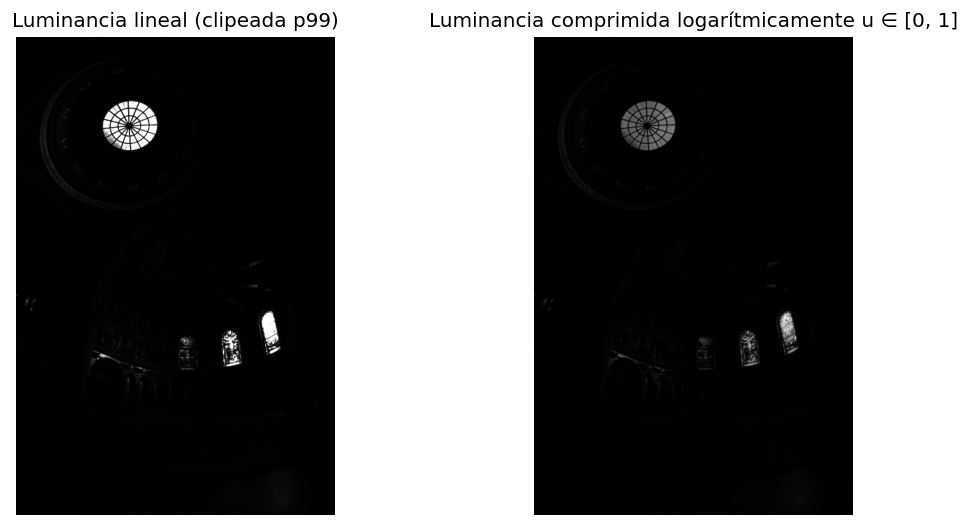

In [10]:
def load_hdr_rgb(path):
    """Carga una imagen HDR/TIFF en formato float64 RGB."""
    if not os.path.exists(path):
        raise FileNotFoundError(f"No se encontró el archivo: {path}")
    
    if iio is not None:
        img = iio.imread(path).astype(np.float64)
    elif cv2 is not None:
        img = cv2.imread(path, cv2.IMREAD_UNCHANGED)
        if img is None:
            raise ValueError(f"OpenCV no pudo leer: {path}")
        img = img.astype(np.float64)
        if img.ndim == 3:
            img = img[..., ::-1]  # BGR -> RGB
    else:
        raise RuntimeError("Instala imageio o opencv-python para leer la imagen.")
    
    # Si tiene canal alfa, descartarlo
    if img.ndim == 3 and img.shape[2] > 3:
        img = img[..., :3]
    return img


def prepare_luminance(rgb_img, log_strength=15.0):
    """Extrae luminancia, comprime globalmente el rango dinámico y normaliza a [0, 1]."""
    rgb_pos = np.maximum(rgb_img, 0.0)
    if rgb_pos.ndim == 3:
        Y = 0.2126 * rgb_pos[..., 0] + 0.7152 * rgb_pos[..., 1] + 0.0722 * rgb_pos[..., 2]
    else:
        Y = rgb_pos.copy()
    
    # Escalar por percentil 99.9 para evitar que outliers extremos aplasten la compresión
    scale_ref = np.percentile(Y, 99.9)
    if scale_ref <= 0:
        scale_ref = np.max(Y) if np.max(Y) > 0 else 1.0
    Y_scaled = Y / scale_ref
    
    # Compresión global logarítmica y normalización estricta a [0, 1]
    Y_comp = np.log1p(log_strength * Y_scaled)
    Y_norm = (Y_comp - Y_comp.min()) / (Y_comp.max() - Y_comp.min())
    return Y, Y_norm


img_path = os.path.join("archivos_t4", "memorial.tif")
rgb_hdr = load_hdr_rgb(img_path)
Y_raw, u = prepare_luminance(rgb_hdr, log_strength=15.0)

print(f"Imagen cargada: {img_path}")
print(f"Shape RGB: {rgb_hdr.shape} | Dtype original: {rgb_hdr.dtype}")
print(f"Rango luminancia bruta Y: [{Y_raw.min():.4e}, {Y_raw.max():.4e}]")
print(f"Rango luminancia comprimida u: [{u.min():.4f}, {u.max():.4f}] | Shape: {u.shape}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].imshow(np.clip(Y_raw / np.percentile(Y_raw, 99), 0, 1), cmap="gray")
axes[0].set_title("Luminancia lineal (clipeada p99)")
axes[0].axis("off")

axes[1].imshow(u, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Luminancia comprimida logarítmicamente u ∈ [0, 1]")
axes[1].axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "00_luminancia_entrada.png", bbox_inches="tight")
plt.show()

## 1. Implementación: Pirámide Laplaciana y Transformada Starlet

### Decisiones de diseño:
- **Filtro de suavizado base:** Kernel separable B3-spline 1D $h = \frac{1}{16}[1, 4, 6, 4, 1]$ (suma igual a $1$), aplicado mediante convolución separable por filas y columnas con condiciones de borde reflejadas (`mode='reflect'`).
- **Pirámide Laplaciana (decimada):**
  - *Reducción ($D$):* Convolución 2D separable con $h$ seguida de submuestreo por factor 2 (`[::2, ::2]`).
  - *Expansión ($U$):* Inserción de ceros en posiciones impares hasta recuperar las dimensiones exactas `(H_prev, W_prev)` del nivel superior, seguida de convolución separable con $2h$ en cada eje (factor total $4$, preservando la ganancia DC unitaria).
  - *Capa de detalle:* $d_j = c_{j-1} - U(c_j)$ para $j = 1, \dots, 5$.
  - *Reconstrucción:* $\hat{c}_{j-1} = d_j + U(\hat{c}_j)$ desde $\hat{c}_5 = c_5$.
- **Transformada Starlet (no decimada, *à trous*):**
  - En cada escala $j = 1, \dots, 5$, se insertan $2^{j-1} - 1$ ceros entre los coeficientes de $h$ para formar $h^{(j)}$.
  - *Aproximación:* $c_j = c_{j-1} * h^{(j)}_{2D}$ (convolución separable con `mode='reflect'`).
  - *Capa de detalle:* $w_j = c_{j-1} - c_j$.
  - *Reconstrucción:* $\hat{c}_0 = c_5 + \sum_{j=1}^5 w_j$.

In [11]:
# Kernel B3-spline 1D base
H_B3 = np.array([1.0, 4.0, 6.0, 4.0, 1.0], dtype=np.float64) / 16.0


def conv2d_separable(img, kernel_1d, mode="reflect"):
    """Convolución 2D separable aplicando un filtro 1D por filas y columnas."""
    temp = convolve1d(img, kernel_1d, axis=0, mode=mode)
    out = convolve1d(temp, kernel_1d, axis=1, mode=mode)
    return out


# ==============================================================================
# A) PIRÁMIDE LAPLACIANA DECIMADA
# ==============================================================================
def laplacian_reduce(img, kernel_1d=H_B3):
    """Suaviza con h y diezma por factor 2 en ambos ejes."""
    smoothed = conv2d_separable(img, kernel_1d, mode="reflect")
    return smoothed[::2, ::2]


def laplacian_expand(img, target_shape, kernel_1d=H_B3):
    """Expande insertando ceros hasta target_shape y suaviza con 2*h por eje."""
    H_t, W_t = target_shape
    upsampled = np.zeros((H_t, W_t), dtype=np.float64)
    upsampled[::2, ::2] = img
    # Factor 2 por cada dimensión (2 * 2 = 4 en 2D) para mantener ganancia DC = 1
    return conv2d_separable(upsampled, 2.0 * kernel_1d, mode="reflect")


def laplacian_pyramid_decompose(img, num_scales=5, kernel_1d=H_B3):
    """Descompone una imagen 2D en num_scales capas de detalle y 1 residual."""
    c_curr = img.astype(np.float64).copy()
    details = []
    for _ in range(num_scales):
        c_next = laplacian_reduce(c_curr, kernel_1d=kernel_1d)
        c_up = laplacian_expand(c_next, target_shape=c_curr.shape, kernel_1d=kernel_1d)
        d_j = c_curr - c_up
        details.append(d_j)
        c_curr = c_next
    residual = c_curr
    return details, residual


def laplacian_pyramid_reconstruct(details, residual, kernel_1d=H_B3):
    """Reconstruye la imagen desde las capas de detalle y el residual."""
    c_curr = residual.astype(np.float64).copy()
    for d_j in reversed(details):
        c_up = laplacian_expand(c_curr, target_shape=d_j.shape, kernel_1d=kernel_1d)
        c_curr = d_j + c_up
    return c_curr


# ==============================================================================
# B) TRANSFORMADA STARLET (ALGORITMO À TROUS)
# ==============================================================================
def build_atrous_kernel(kernel_1d, scale_idx):
    """Inserta 2^(scale_idx - 1) - 1 ceros entre coeficientes (scale_idx >= 1)."""
    step = 2 ** (scale_idx - 1)
    if step == 1:
        return kernel_1d.copy()
    atrous_len = (len(kernel_1d) - 1) * step + 1
    k_atrous = np.zeros(atrous_len, dtype=np.float64)
    k_atrous[::step] = kernel_1d
    return k_atrous


def starlet_decompose(img, num_scales=5, kernel_1d=H_B3):
    """Descompone una imagen 2D mediante transformada starlet de num_scales escalas."""
    c_curr = img.astype(np.float64).copy()
    details = []
    for j in range(1, num_scales + 1):
        k_j = build_atrous_kernel(kernel_1d, j)
        c_next = conv2d_separable(c_curr, k_j, mode="reflect")
        w_j = c_curr - c_next
        details.append(w_j)
        c_curr = c_next
    residual = c_curr
    return details, residual


def starlet_reconstruct(details, residual):
    """Reconstruye la imagen sumando las capas starlet y el residual grueso."""
    recon = residual.astype(np.float64).copy()
    for w_j in details:
        recon += w_j
    return recon


# ==============================================================================
# VALIDACIÓN DE RECONSTRUCCIÓN SIN MODIFICACIÓN DE COEFICIENTES
# ==============================================================================
NUM_SCALES = 5

lap_details, lap_res = laplacian_pyramid_decompose(u, num_scales=NUM_SCALES)
u_rec_lap = laplacian_pyramid_reconstruct(lap_details, lap_res)

star_details, star_res = starlet_decompose(u, num_scales=NUM_SCALES)
u_rec_star = starlet_reconstruct(star_details, star_res)

rmse_lap = np.sqrt(np.mean((u - u_rec_lap) ** 2))
max_err_lap = np.max(np.abs(u - u_rec_lap))

rmse_star = np.sqrt(np.mean((u - u_rec_star) ** 2))
max_err_star = np.max(np.abs(u - u_rec_star))

print("=== Validación de Reconstrucción Exacta (5 escalas + residual) ===")
print(f"Pirámide Laplaciana -> RMSE: {rmse_lap:.4e} | Error máx abs: {max_err_lap:.4e}")
print(f"Transformada Starlet -> RMSE: {rmse_star:.4e} | Error máx abs: {max_err_star:.4e}")

=== Validación de Reconstrucción Exacta (5 escalas + residual) ===
Pirámide Laplaciana -> RMSE: 1.1811e-18 | Error máx abs: 2.2204e-16
Transformada Starlet -> RMSE: 3.4484e-18 | Error máx abs: 1.1102e-16


## 2. Experimentación y Análisis

### Experimento 1: Visualización de las 5 capas de detalle y el residual grueso
Para facilitar la comparación entre escalas y entre ambas representaciones:
- Todas las **capas de detalle** ($d_j$ y $w_j$) se visualizan centradas en cero con un mapa divergente (`RdBu_r`) y rango simétrico $[-M, M]$ común (usando el percentil 99.5 de $|d_1|$ y $|w_1|$ o máximo compartido para evitar que extremos puntuales apaguen las escalas).
- Los **residuales gruesos** ($c_5$) se muestran en escala de grises $[0, 1]$.
- Se reportan explícitamente las dimensiones `(H, W)` y el número de coeficientes de cada capa.

Dimensiones y cantidad de coeficientes por nivel:
  Escala 1: Laplaciana d_1 = (768, 512) (393,216 coefs) | Starlet w_1 = (768, 512) (393,216 coefs)
  Escala 2: Laplaciana d_2 = (384, 256) (98,304 coefs) | Starlet w_2 = (768, 512) (393,216 coefs)
  Escala 3: Laplaciana d_3 = (192, 128) (24,576 coefs) | Starlet w_3 = (768, 512) (393,216 coefs)
  Escala 4: Laplaciana d_4 = (96, 64) (6,144 coefs) | Starlet w_4 = (768, 512) (393,216 coefs)
  Escala 5: Laplaciana d_5 = (48, 32) (1,536 coefs) | Starlet w_5 = (768, 512) (393,216 coefs)
  Residual : Laplaciana c_5 = (24, 16) (384 coefs) | Starlet c_5 = (768, 512) (393,216 coefs)
Total coeficientes -> Original: 393,216 | Laplaciana: 524,160 (1.33x) | Starlet: 2,359,296 (6.00x)


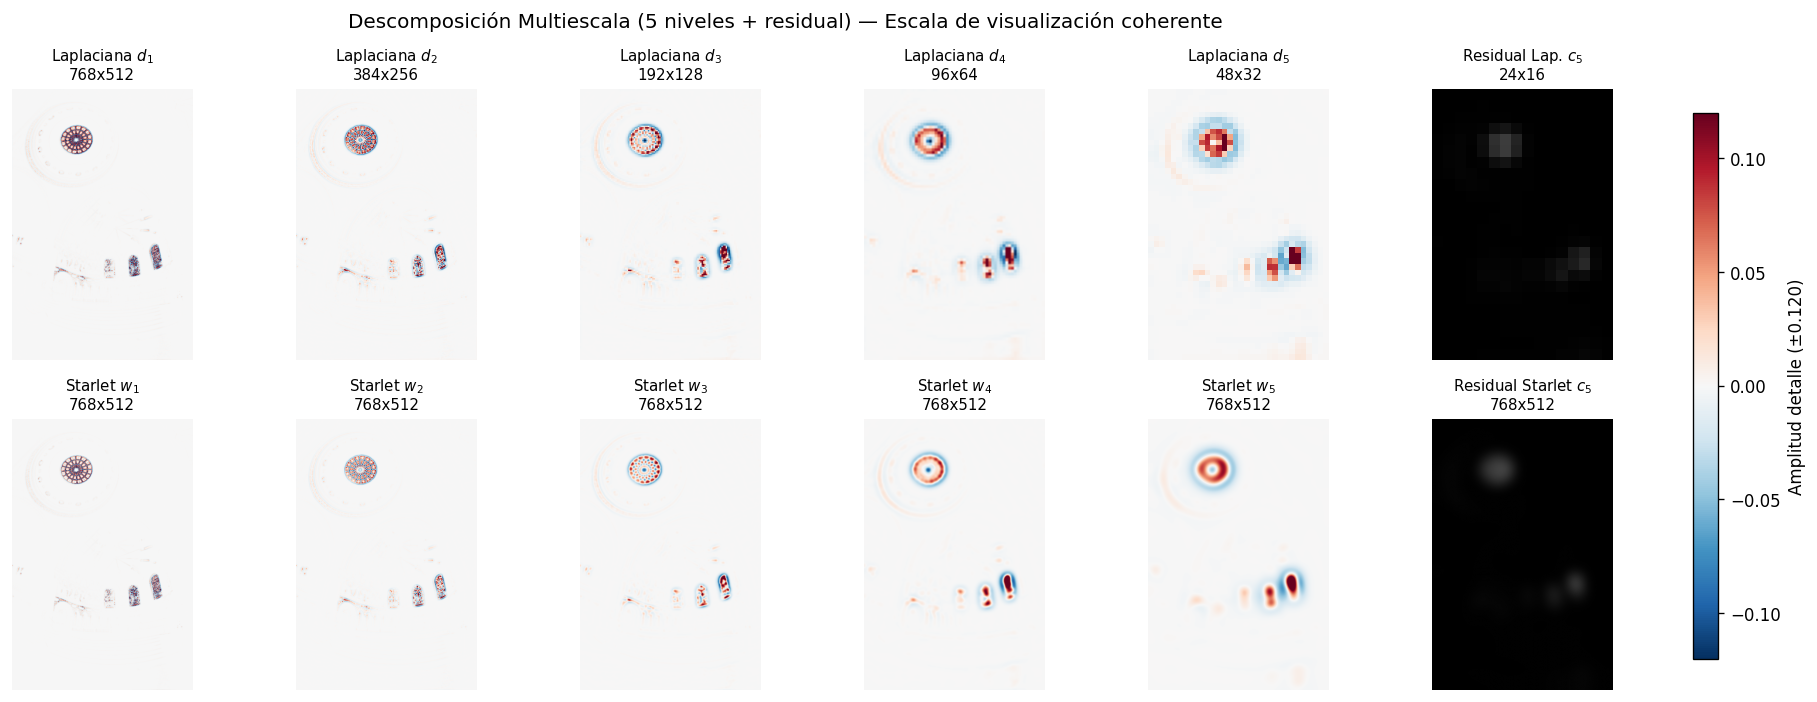

In [12]:
print("Dimensiones y cantidad de coeficientes por nivel:")
total_pixels = u.size
total_lap_coeffs = sum(d.size for d in lap_details) + lap_res.size
total_star_coeffs = sum(w.size for w in star_details) + star_res.size

for j in range(NUM_SCALES):
    print(f"  Escala {j+1}: Laplaciana d_{j+1} = {lap_details[j].shape} ({lap_details[j].size:,} coefs) | "
          f"Starlet w_{j+1} = {star_details[j].shape} ({star_details[j].size:,} coefs)")
print(f"  Residual : Laplaciana c_5 = {lap_res.shape} ({lap_res.size:,} coefs) | "
      f"Starlet c_5 = {star_res.shape} ({star_res.size:,} coefs)")
print(f"Total coeficientes -> Original: {total_pixels:,} | "
      f"Laplaciana: {total_lap_coeffs:,} ({total_lap_coeffs/total_pixels:.2f}x) | "
      f"Starlet: {total_star_coeffs:,} ({total_star_coeffs/total_pixels:.2f}x)")

# Rango simétrico coherente para las capas de detalle
vmax_shared = max(
    np.percentile(np.abs(lap_details[0]), 99.5),
    np.percentile(np.abs(star_details[0]), 99.5)
)

fig, axes = plt.subplots(2, NUM_SCALES + 1, figsize=(18, 6.5))

for j in range(NUM_SCALES):
    # Fila 0: Pirámide Laplaciana
    ax_l = axes[0, j]
    im_l = ax_l.imshow(lap_details[j], cmap="RdBu_r", vmin=-vmax_shared, vmax=vmax_shared)
    ax_l.set_title(f"Laplaciana $d_{j+1}$\n{lap_details[j].shape[0]}x{lap_details[j].shape[1]}", fontsize=9)
    ax_l.axis("off")

    # Fila 1: Starlet
    ax_s = axes[1, j]
    im_s = ax_s.imshow(star_details[j], cmap="RdBu_r", vmin=-vmax_shared, vmax=vmax_shared)
    ax_s.set_title(f"Starlet $w_{j+1}$\n{star_details[j].shape[0]}x{star_details[j].shape[1]}", fontsize=9)
    ax_s.axis("off")

# Residuales en la última columna
axes[0, NUM_SCALES].imshow(lap_res, cmap="gray", vmin=0, vmax=1)
axes[0, NUM_SCALES].set_title(f"Residual Lap. $c_5$\n{lap_res.shape[0]}x{lap_res.shape[1]}", fontsize=9)
axes[0, NUM_SCALES].axis("off")

axes[1, NUM_SCALES].imshow(star_res, cmap="gray", vmin=0, vmax=1)
axes[1, NUM_SCALES].set_title(f"Residual Starlet $c_5$\n{star_res.shape[0]}x{star_res.shape[1]}", fontsize=9)
axes[1, NUM_SCALES].axis("off")

cbar_ax = fig.add_axes([0.92, 0.15, 0.012, 0.7])
fig.colorbar(im_s, cax=cbar_ax, label=f"Amplitud detalle (±{vmax_shared:.3f})")
plt.suptitle("Descomposición Multiescala (5 niveles + residual) — Escala de visualización coherente", fontsize=12)
plt.subplots_adjust(right=0.90, wspace=0.12, hspace=0.22)
plt.savefig(OUTPUT_DIR / "01_capas_detalle_y_residual.png", bbox_inches="tight")
plt.show()

### Lectura de la descomposicion

En esta imagen de $768\times512$ pixeles, la piramide produce capas de detalle cada vez menores ($768\times512$ hasta $48\times32$) y un residual de $24\times16$. En starlet, las cinco capas de detalle y el residual conservan el tamano $768\times512$. El conteo observado es de 524 160 coeficientes para la piramide (1,33 veces la entrada) y 2 359 296 para starlet (6 veces): la primera reduce el costo espacial al decimar; la segunda conserva la grilla completa en todas las escalas.

El limite de color compartido de los detalles se fija con el percentil 99,5 de las capas mas finas para comparar amplitudes con la misma escala visual sin dejar que unos pocos valores extremos oculten el resto de la estructura.

### Experimento 2: Umbral duro relativo ($T_j = \alpha \cdot \max|d_j|$)

Aplicamos umbral duro $T_j = \alpha \cdot \max|d_j|$ (y análogamente $T_j = \alpha \cdot \max|w_j|$ en starlets) sobre las 5 capas de detalle dejando intacto el residual $c_5$. Evaluamos $\alpha \in \{0.05, 0.15, 0.30\}$ (tres valores comunes para observar claramente la progresión de pérdida de detalle y aparición de artefactos), reportamos el porcentaje de coeficientes no nulos conservados por capa y calculamos el RMSE de reconstrucción.

=== Porcentaje de coeficientes conservados por capa y RMSE de reconstrucción ===

--- alpha = 0.05 ---
  Laplaciana (% por capa d1..d5): [2.32, 3.35, 3.86, 5.14, 9.24] | Total detalle: 2.64% | RMSE: 0.0049
  Starlet    (% por capa w1..w5): [2.24, 2.79, 3.68, 4.21, 7.01] | Total detalle: 3.99% | RMSE: 0.0046

--- alpha = 0.15 ---
  Laplaciana (% por capa d1..d5): [1.11, 1.78, 1.6, 2.05, 3.06] | Total detalle: 1.28% | RMSE: 0.0133
  Starlet    (% por capa w1..w5): [1.14, 1.41, 1.66, 1.42, 2.25] | Total detalle: 1.57% | RMSE: 0.0121

--- alpha = 0.30 ---
  Laplaciana (% por capa d1..d5): [0.34, 0.71, 0.48, 0.42, 0.91] | Total detalle: 0.42% | RMSE: 0.0242
  Starlet    (% por capa w1..w5): [0.43, 0.36, 0.59, 0.31, 0.59] | Total detalle: 0.46% | RMSE: 0.0229


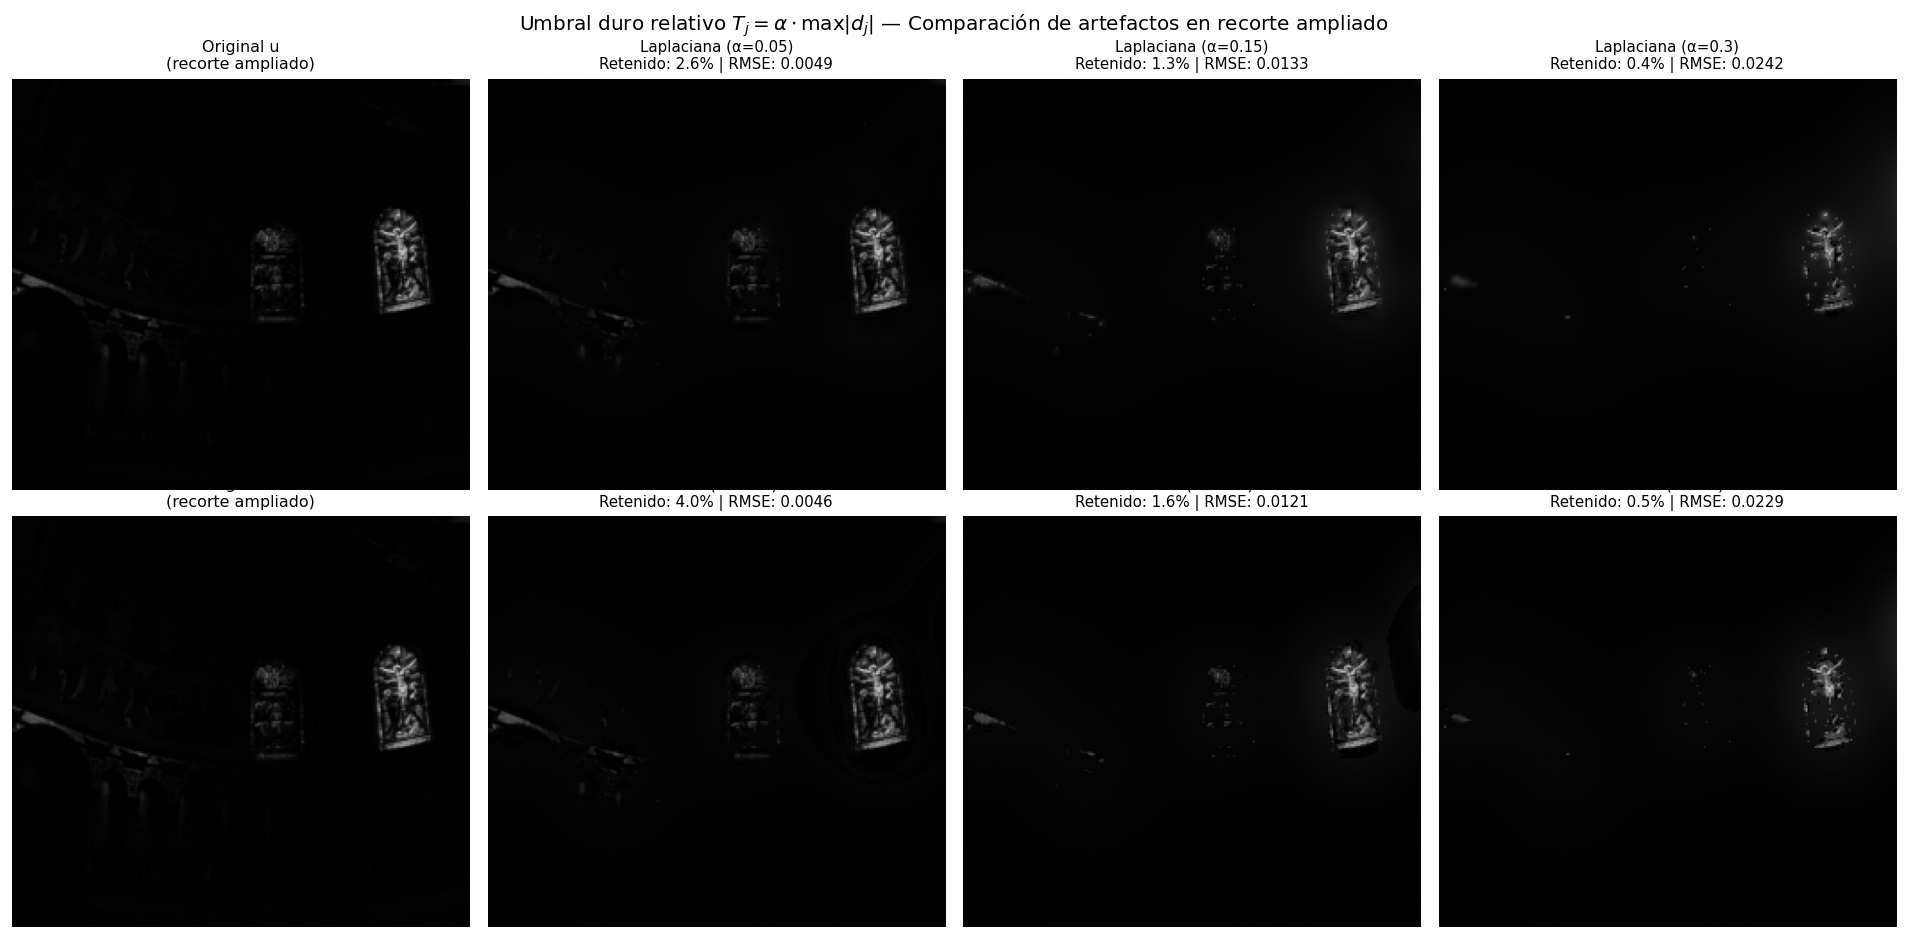

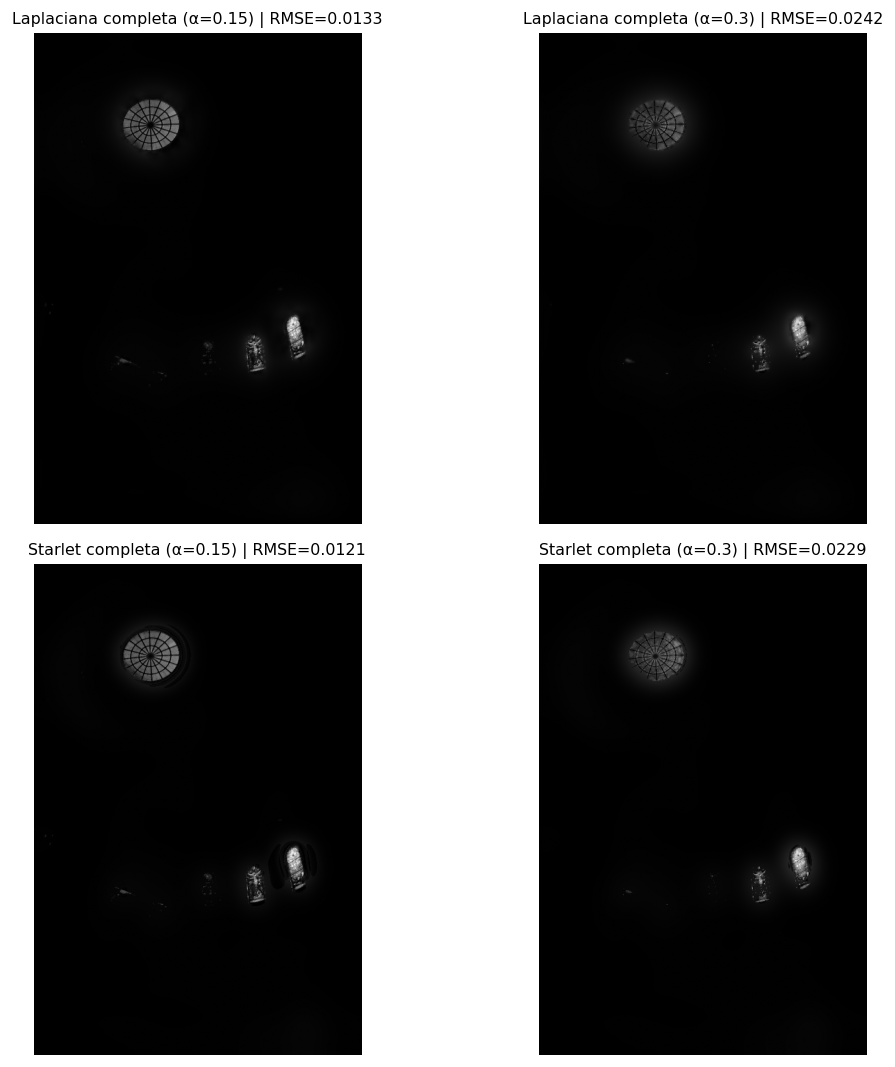

In [13]:
def hard_threshold_layers(details, alpha):
    """Aplica umbral duro relativo T_j = alpha * max(|d_j|) por capa."""
    thresh_details = []
    kept_percentages = []
    for layer in details:
        T_j = alpha * np.max(np.abs(layer))
        mask = np.abs(layer) >= T_j
        layer_t = np.where(mask, layer, 0.0)
        pct = 100.0 * np.sum(mask) / layer.size
        thresh_details.append(layer_t)
        kept_percentages.append(pct)
    return thresh_details, kept_percentages


alphas = [0.05, 0.15, 0.30]
results_thresh = {"lap": {}, "star": {}}

print("=== Porcentaje de coeficientes conservados por capa y RMSE de reconstrucción ===")
for alpha in alphas:
    lap_t, lap_pcts = hard_threshold_layers(lap_details, alpha)
    rec_l_unclipped = laplacian_pyramid_reconstruct(lap_t, lap_res)
    rmse_l = np.sqrt(np.mean((u - rec_l_unclipped) ** 2))
    rec_l = np.clip(rec_l_unclipped, 0.0, 1.0)
    total_pct_l = 100.0 * sum(np.count_nonzero(x) for x in lap_t) / sum(x.size for x in lap_t)

    star_t, star_pcts = hard_threshold_layers(star_details, alpha)
    rec_s_unclipped = starlet_reconstruct(star_t, star_res)
    rmse_s = np.sqrt(np.mean((u - rec_s_unclipped) ** 2))
    rec_s = np.clip(rec_s_unclipped, 0.0, 1.0)
    total_pct_s = 100.0 * sum(np.count_nonzero(x) for x in star_t) / sum(x.size for x in star_t)

    results_thresh["lap"][alpha] = (rec_l, lap_pcts, total_pct_l, rmse_l)
    results_thresh["star"][alpha] = (rec_s, star_pcts, total_pct_s, rmse_s)

    print(f"\n--- alpha = {alpha:.2f} ---")
    print("  Laplaciana (% por capa d1..d5):", [round(float(p), 2) for p in lap_pcts],
          f"| Total detalle: {total_pct_l:.2f}% | RMSE: {rmse_l:.4f}")
    print("  Starlet    (% por capa w1..w5):", [round(float(p), 2) for p in star_pcts],
          f"| Total detalle: {total_pct_s:.2f}% | RMSE: {rmse_s:.4f}")

# Coordenadas de recorte para inspeccionar detalles finos (vitral/arcos superiores)
H, W = u.shape
r0, r1 = int(0.52 * H), int(0.82 * H)
c0, c1 = int(0.25 * W), int(0.75 * W)

fig, axes = plt.subplots(2, len(alphas) + 1, figsize=(16, 8))

# Columna 0: Referencia original (completa y recorte)
original_crop = u[r0:r1, c0:c1]
axes[0, 0].imshow(original_crop, cmap="gray", vmin=0, vmax=1)
axes[0, 0].set_title("Original u\n(recorte ampliado)", fontsize=9.5)
axes[0, 0].axis("off")

axes[1, 0].imshow(original_crop, cmap="gray", vmin=0, vmax=1)
axes[1, 0].set_title("Original u\n(recorte ampliado)", fontsize=9.5)
axes[1, 0].axis("off")

for idx, alpha in enumerate(alphas, start=1):
    rec_l, _, pct_l, rmse_l = results_thresh["lap"][alpha]
    rec_s, _, pct_s, rmse_s = results_thresh["star"][alpha]

    # Mostrar recortes ampliados de ambos métodos para comparar artefactos claramente
    axes[0, idx].imshow(rec_l[r0:r1, c0:c1], cmap="gray", vmin=0, vmax=1)
    axes[0, idx].set_title(f"Laplaciana (α={alpha})\nRetenido: {pct_l:.1f}% | RMSE: {rmse_l:.4f}", fontsize=9)
    axes[0, idx].axis("off")

    axes[1, idx].imshow(rec_s[r0:r1, c0:c1], cmap="gray", vmin=0, vmax=1)
    axes[1, idx].set_title(f"Starlet (α={alpha})\nRetenido: {pct_s:.1f}% | RMSE: {rmse_s:.4f}", fontsize=9)
    axes[1, idx].axis("off")

plt.suptitle(r"Umbral duro relativo $T_j = \alpha \cdot \max|d_j|$ — Comparación de artefactos en recorte ampliado", fontsize=12)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_umbral_duro_comparacion.png", bbox_inches="tight")
plt.show()

# Figura adicional con las imágenes completas para alpha = 0.15 y 0.30
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for idx, alpha in enumerate([0.15, 0.30]):
    rec_l, _, pct_l, rmse_l = results_thresh["lap"][alpha]
    rec_s, _, pct_s, rmse_s = results_thresh["star"][alpha]
    axes[0, idx].imshow(rec_l, cmap="gray", vmin=0, vmax=1)
    axes[0, idx].set_title(f"Laplaciana completa (α={alpha}) | RMSE={rmse_l:.4f}", fontsize=9.5)
    axes[0, idx].axis("off")

    axes[1, idx].imshow(rec_s, cmap="gray", vmin=0, vmax=1)
    axes[1, idx].set_title(f"Starlet completa (α={alpha}) | RMSE={rmse_s:.4f}", fontsize=9.5)
    axes[1, idx].axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02b_umbral_duro_completas.png", bbox_inches="tight")
plt.show()

### Lectura del umbralizado

Al aumentar $\alpha$ de 0,05 a 0,30, el porcentaje total retenido en las capas de detalle cae de 2,64 % a 0,42 % en la piramide y de 3,99 % a 0,46 % en starlet. En paralelo, el RMSE medido antes del clipping sube de 0,0049 a 0,0242 y de 0,0046 a 0,0229, respectivamente. En el recorte se van perdiendo subdivisiones menos contrastadas de los vitrales; alrededor de algunos bordes tambien se aprecian halos, mas visibles en starlet. El residual se mantiene sin umbralizar.

Aunque se usa el mismo $\alpha$ relativo por escala, las dos representaciones no retienen el mismo porcentaje de coeficientes (por ejemplo, con $\alpha=0,15$: 1,28 % frente a 1,57 % del total de detalles). Por eso los RMSE deben leerse junto con las tasas de retencion y las figuras, no como una comparacion a igual cantidad de coeficientes. El clipping a $[0,1]$ se aplica solo a las imagenes mostradas; el RMSE se calcula sobre la reconstruccion sin clipping.

### Experimento 3: Modificación mediante factores multiplicativos por escala

Aplicamos exactamente el mismo vector de ganancias $g = [g_1, g_2, g_3, g_4, g_5]$ a ambas representaciones (manteniendo $c_5$ sin cambios):
1. **Configuración A (Énfasis en estructuras finas):** $g_{\text{fino}} = [2.5, 2.0, 1.3, 1.0, 1.0]$ — realza texturas de alta frecuencia (ladrillos, bordes de vitrales, detalles arquitectónicos).
2. **Configuración B (Énfasis en estructuras de mayor escala):** $g_{\text{grueso}} = [1.0, 1.0, 1.3, 2.0, 2.5]$ — realza contrastes macro y transiciones espaciales amplias (arcos, columnas, volúmenes).

Comparamos las imágenes reconstruidas completas y un recorte ampliado donde se evidencian diferencias de halos/overshoot entre la pirámide decimada y starlets.

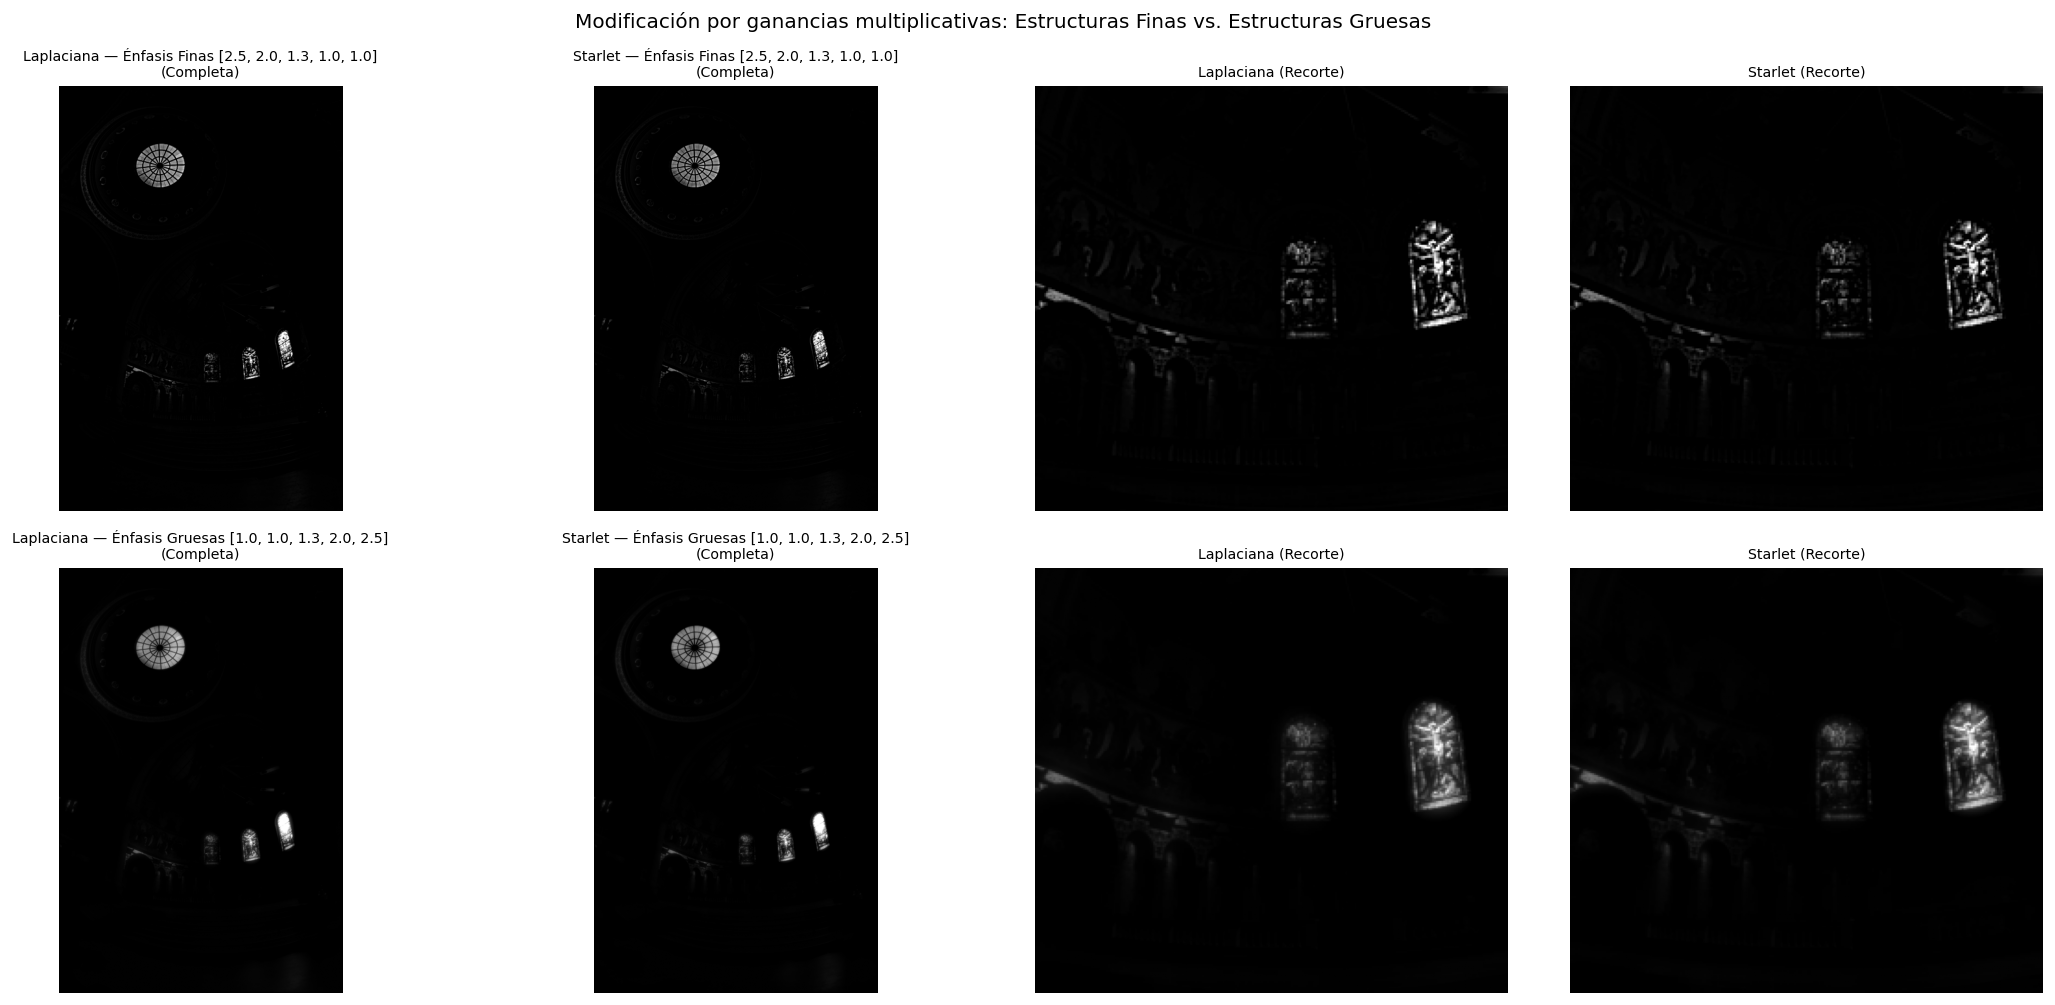

In [14]:
def apply_scale_gains(details, gains):
    assert len(details) == len(gains)
    return [g * layer for g, layer in zip(gains, details)]


gains_fine = [2.5, 2.0, 1.3, 1.0, 1.0]
gains_coarse = [1.0, 1.0, 1.3, 2.0, 2.5]

configs = [
    ("Énfasis Finas [2.5, 2.0, 1.3, 1.0, 1.0]", gains_fine),
    ("Énfasis Gruesas [1.0, 1.0, 1.3, 2.0, 2.5]", gains_coarse),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

# Columna 0: Original
axes[0, 0].imshow(u, cmap="gray", vmin=0, vmax=1)
axes[0, 0].set_title("Original u (completa)", fontsize=10)
axes[0, 0].axis("off")

axes[1, 0].imshow(u[r0:r1, c0:c1], cmap="gray", vmin=0, vmax=1)
axes[1, 0].set_title("Original u (recorte)", fontsize=10)
axes[1, 0].axis("off")

# Columna 1: Laplaciana - Finas vs Gruesas (mostramos ambas configuraciones en figuras separadas y recorte junto)
plt.close(fig)

fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
for row_idx, (label, g_vec) in enumerate(configs):
    rec_l = np.clip(laplacian_pyramid_reconstruct(apply_scale_gains(lap_details, g_vec), lap_res), 0.0, 1.0)
    rec_s = np.clip(starlet_reconstruct(apply_scale_gains(star_details, g_vec), star_res), 0.0, 1.0)

    axes[row_idx, 0].imshow(rec_l, cmap="gray", vmin=0, vmax=1)
    axes[row_idx, 0].set_title(f"Laplaciana — {label}\n(Completa)", fontsize=8.5)
    axes[row_idx, 0].axis("off")

    axes[row_idx, 1].imshow(rec_s, cmap="gray", vmin=0, vmax=1)
    axes[row_idx, 1].set_title(f"Starlet — {label}\n(Completa)", fontsize=8.5)
    axes[row_idx, 1].axis("off")

    axes[row_idx, 2].imshow(rec_l[r0:r1, c0:c1], cmap="gray", vmin=0, vmax=1)
    axes[row_idx, 2].set_title(f"Laplaciana (Recorte)", fontsize=8.5)
    axes[row_idx, 2].axis("off")

    axes[row_idx, 3].imshow(rec_s[r0:r1, c0:c1], cmap="gray", vmin=0, vmax=1)
    axes[row_idx, 3].set_title(f"Starlet (Recorte)", fontsize=8.5)
    axes[row_idx, 3].axis("off")

plt.suptitle("Modificación por ganancias multiplicativas: Estructuras Finas vs. Estructuras Gruesas", fontsize=12)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_ganancias_multiescala.png", bbox_inches="tight")
plt.show()

### Lectura de las ganancias por escala

La configuracion de enfasis fino ($[2.5,2.0,1.3,1.0,1.0]$) realza principalmente contornos y subdivisiones pequenas, visibles en los marcos de los vitrales. La configuracion de enfasis grueso ($[1.0,1.0,1.3,2.0,2.5]$) aumenta la contribucion de estructuras amplias y transiciones suaves; el recorte permite contrastar esos cambios en la arquitectura. En ambos casos se conservan las ganancias por escala definidas para cada metodo y las imagenes se limitan a $[0,1]$ para su visualizacion.